# TCGA-KIRC: survival association testing

## Aim

This notebook tests associations between pre-specified immune/inflammation expression features and overall survival in the matched TCGA-KIRC cohort.

Primary analyses test the three signature scores. Secondary analyses test the 14 individual panel genes. Every Cox model adjusts for age, sex, and grade and is stratified by pathological stage, consistent with the Stage 02 clinical model.

05-01 Importing packages

In [19]:
# 05-02  importing files
from pathlib import Path

import numpy as np
import pandas as pd

from lifelines import CoxPHFitter
from statsmodels.stats.multitest import multipletests

05-02 Loading packages and analysis data

In [20]:
# 05-02  loading analysis data

PROJECT_DIR = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"

clinical_signature_file = (
    PROCESSED_DATA_DIR
    / "tcga_kirc_clinical_immune_signature_analysis_data.csv"
)

zscore_file = (
    PROCESSED_DATA_DIR
    / "tcga_kirc_log2_tpm_zscore_protein_coding_by_patient.pkl.gz"
)

panel_definition_file = (
    PROJECT_DIR / "docs" / "immune_inflammation_gene_panel.csv"
)

clinical_signature_data = pd.read_csv(clinical_signature_file)
expression_zscore = pd.read_pickle(zscore_file)
panel_definition = pd.read_csv(panel_definition_file)

assert clinical_signature_data["patient_id"].tolist() == expression_zscore.columns.tolist()

print("Patients:", len(clinical_signature_data))
print("Deaths:", clinical_signature_data["event_observed"].sum())
print("Expression matrix:", expression_zscore.shape)
print("Panel genes:", len(panel_definition))

Patients: 518
Deaths: 171
Expression matrix: (19524, 518)
Panel genes: 14


05-03 Preparing clinical adjustment variables

In [12]:
# 05-03 Preparing clinical adjustment variables

analysis_data = clinical_signature_data.copy()

analysis_data["age_per_10_years"] = (
    analysis_data["age_at_index"] / 10
)

analysis_data["male"] = (
    analysis_data["sex_at_birth"] == "male"
).astype(int)

analysis_data["high_grade"] = (
    analysis_data["tumor_grade"].isin(["G3", "G4"])
).astype(int)

signature_columns = [
    "effector_t_cell_score",
    "immune_checkpoint_score",
    "myeloid_inflammation_score",
]

for signature in signature_columns:
    analysis_data[f"{signature}_per_sd"] = (
        analysis_data[signature] - analysis_data[signature].mean()
    ) / analysis_data[signature].std()

clinical_covariates = [
    "age_per_10_years",
    "male",
    "high_grade",
]

required_columns = [
    "overall_survival_days",
    "event_observed",
    "tumor_stage",
] + clinical_covariates + [
    f"{signature}_per_sd" for signature in signature_columns
]

assert analysis_data[required_columns].notna().all().all()

print("Patients:", len(analysis_data))
print("Deaths:", analysis_data["event_observed"].sum())

print("\nPathological-stage counts:")
display(analysis_data["tumor_stage"].value_counts().sort_index())

print("\nGrade-group counts:")
display(
    analysis_data["high_grade"]
    .map({0: "G1/G2 (low grade)", 1: "G3/G4 (high grade)"})
    .value_counts()
)

Patients: 518
Deaths: 171

Pathological-stage counts:


tumor_stage
Stage I      259
Stage II      54
Stage III    122
Stage IV      83
Name: count, dtype: int64


Grade-group counts:


high_grade
G3/G4 (high grade)    279
G1/G2 (low grade)     239
Name: count, dtype: int64

05-04 Refitting the clinical baseline model in the 518-patient cohort

In [3]:
# 05-04 Refitting the clinical baseline model in the matched cohort

baseline_columns = [
    "overall_survival_days",
    "event_observed",
    "tumor_stage",
] + clinical_covariates

baseline_model_data = analysis_data[baseline_columns].copy()

clinical_baseline_model = CoxPHFitter()

clinical_baseline_model.fit(
    baseline_model_data,
    duration_col="overall_survival_days",
    event_col="event_observed",
    strata=["tumor_stage"],
)

baseline_results = clinical_baseline_model.summary[
    ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]
].copy()

baseline_results.columns = [
    "hazard_ratio",
    "lower_95_CI",
    "upper_95_CI",
    "p_value",
]

print(
    "Clinical baseline concordance index: "
    f"{clinical_baseline_model.concordance_index_:.3f}"
)

display(baseline_results.round(3))

Clinical baseline concordance index: 0.629


,hazard_ratio,lower_95_CI,upper_95_CI,p_value
covariate,,,,
age_per_10_years,1.371,1.184,1.588,0.000
male,0.989,0.718,1.363,0.947
high_grade,1.592,1.100,2.303,0.014


05-05 Test 3 signature scores in adjusted Cox models

In [11]:
# 05-05 Testing associations for the 3 signature scores

signature_model_results = []

for signature in signature_columns:
    standardized_signature = f"{signature}_per_sd"

    model_columns = [
        "overall_survival_days",
        "event_observed",
        "tumor_stage",
    ] + clinical_covariates + [standardized_signature]

    signature_model = CoxPHFitter()

    signature_model.fit(
        analysis_data[model_columns],
        duration_col="overall_survival_days",
        event_col="event_observed",
        strata=["tumor_stage"],
    )

    signature_summary = signature_model.summary.loc[standardized_signature]

    signature_model_results.append(
        {
            "signature": signature,
            "hazard_ratio_per_SD": signature_summary["exp(coef)"],
            "lower_95_CI": signature_summary["exp(coef) lower 95%"],
            "upper_95_CI": signature_summary["exp(coef) upper 95%"],
            "p_value": signature_summary["p"],
            "concordance_index": signature_model.concordance_index_,
        }
    )

signature_results = pd.DataFrame(signature_model_results)

signature_results["fdr_q_value"] = multipletests(
    signature_results["p_value"],
    method="fdr_bh",
)[1]

signature_results["significant_at_FDR_0_05"] = (
    signature_results["fdr_q_value"] < 0.05
)

display(signature_results.round(3))

,signature,hazard_ratio_per_SD,lower_95_CI,upper_95_CI,p_value,concordance_index,fdr_q_value,significant_at_FDR_0_05
0,effector_t_cell_score,0.934,0.801,1.089,0.384,0.631,0.576,False
1,immune_checkpoint_score,1.020,0.878,1.186,0.793,0.630,0.793,False
2,myeloid_inflammation_score,1.350,1.175,1.551,0.000,0.649,0.000,True


The clinical baseline behaves as before: older age and high grade associate with higher hazard.
The effector T-cell and checkpoint scores show no adjusted survival association.
A one-SD higher myeloid-inflammation score is associated with a 35% higher estimated hazard of death (HR 1.350, 95% CI 1.175–1.551), and remains significant after correcting the three score tests.

05-06 Test each of the 14 panel genes

In [10]:
# 05-06 Testing associations for individual panel genes

panel_gene_results = []

patient_ids = analysis_data["patient_id"].tolist()

for gene in panel_definition.itertuples(index=False):
    gene_values = expression_zscore.loc[
        gene.gene_id,
        patient_ids,
    ].to_numpy()

    gene_model_data = analysis_data[
        [
            "overall_survival_days",
            "event_observed",
            "tumor_stage",
        ] + clinical_covariates
    ].copy()

    gene_model_data["gene_expression_per_sd"] = gene_values

    gene_model = CoxPHFitter()

    gene_model.fit(
        gene_model_data,
        duration_col="overall_survival_days",
        event_col="event_observed",
        strata=["tumor_stage"],
    )

    gene_summary = gene_model.summary.loc["gene_expression_per_sd"]

    panel_gene_results.append(
        {
            "gene_group": gene.gene_group,
            "gene_name": gene.gene_name,
            "gene_id": gene.gene_id,
            "hazard_ratio_per_SD": gene_summary["exp(coef)"],
            "lower_95_CI": gene_summary["exp(coef) lower 95%"],
            "upper_95_CI": gene_summary["exp(coef) upper 95%"],
            "p_value": gene_summary["p"],
            "concordance_index": gene_model.concordance_index_,
        }
    )

gene_results = pd.DataFrame(panel_gene_results)

gene_results["fdr_q_value"] = multipletests(
    gene_results["p_value"],
    method="fdr_bh",
)[1]

gene_results["significant_at_FDR_0_05"] = (
    gene_results["fdr_q_value"] < 0.05
)

gene_results = gene_results.sort_values(
    ["fdr_q_value", "p_value"]
).reset_index(drop=True)

display(gene_results.round(3))

,gene_group,gene_name,gene_id,hazard_ratio_per_SD,lower_95_CI,upper_95_CI,p_value,concordance_index,fdr_q_value,significant_at_FDR_0_05
0,Myeloid inflammation,CXCL3,ENSG00000163734.4,1.326,1.168,1.506,0.000,0.647,0.000,True
1,Myeloid inflammation,CXCL2,ENSG00000081041.9,1.301,1.119,1.512,0.001,0.644,0.004,True
2,Myeloid inflammation,IL6,ENSG00000136244.12,1.268,1.102,1.459,0.001,0.646,0.004,True
3,Myeloid inflammation,CXCL1,ENSG00000163739.5,1.217,1.060,1.397,0.005,0.630,0.018,True
4,Myeloid inflammation,PTGS2,ENSG00000073756.12,1.203,1.040,1.393,0.013,0.637,0.037,True
5,Effector T-cell activity,PRF1,ENSG00000180644.8,0.870,0.745,1.016,0.078,0.637,0.177,False
6,Immune checkpoint,CTLA4,ENSG00000163599.17,1.143,0.980,1.334,0.088,0.631,0.177,False
7,Immune checkpoint,CD274,ENSG00000120217.14,0.883,0.750,1.040,0.136,0.633,0.237,False
8,Effector T-cell activity,EOMES,ENSG00000163508.13,0.896,0.766,1.047,0.166,0.630,0.243,False
9,Effector T-cell activity,GZMA,ENSG00000145649.8,0.899,0.771,1.048,0.174,0.633,0.243,False


As I see this  is internally coherent pattern: all five myeloid-inflammation genes have HRs above 1 (and remain significant after FDR correction). Inference: The signature result is therefore not being driven by only one gene

05-07Save the results 

In [21]:
# 05-07 Saving the results 

RESULTS_TABLE_DIR = RESULTS_DIR / "tables"
RESULTS_TABLE_DIR.mkdir(parents=True, exist_ok=True)

signature_results_file = (
    RESULTS_TABLE_DIR / "table_03_signature_score_adjusted_cox_results.csv"
)

gene_results_file = (
    RESULTS_TABLE_DIR / "table_04_panel_gene_adjusted_cox_results.csv"
)

signature_results.to_csv(signature_results_file, index=False)
gene_results.to_csv(gene_results_file, index=False)

print(f"Signature results saved as: {signature_results_file.name}")
print(f"Gene-level results saved as: {gene_results_file.name}")

Signature results saved as: table_03_signature_score_adjusted_cox_results.csv
Gene-level results saved as: table_04_panel_gene_adjusted_cox_results.csv


05-08 Forest plots for signature and gene results

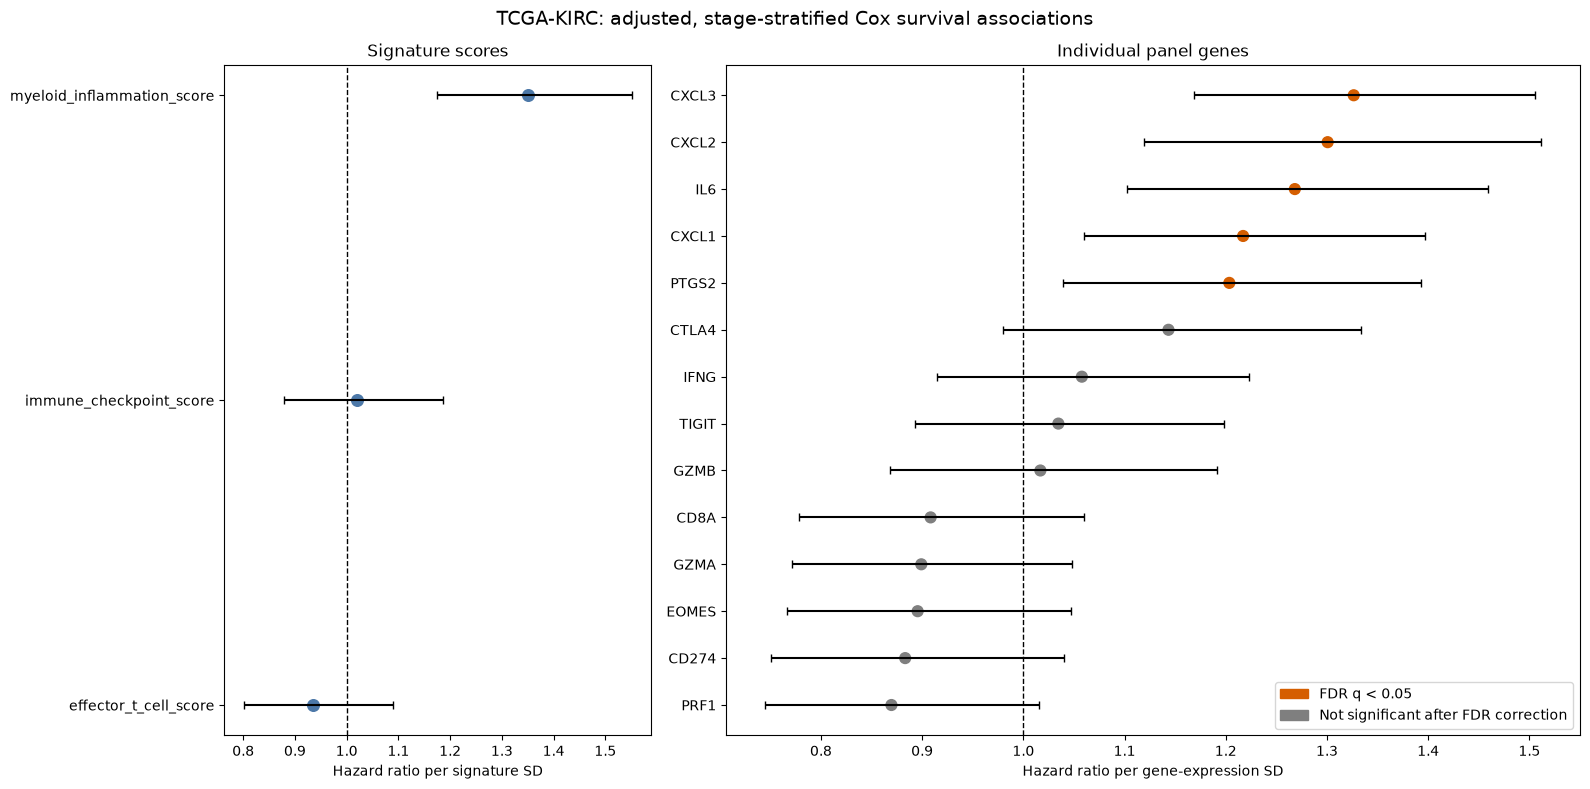

Figure saved as: figure_08_adjusted_cox_associations.png


In [9]:
# 05-08 Creating adjusted Cox-model forest plots

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

signature_plot_data = signature_results.sort_values(
    "hazard_ratio_per_SD"
).copy()

gene_plot_data = gene_results.sort_values(
    "hazard_ratio_per_SD"
).copy()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 8),
    gridspec_kw={"width_ratios": [1, 2]},
)

signature_positions = np.arange(len(signature_plot_data))

axes[0].errorbar(
    signature_plot_data["hazard_ratio_per_SD"],
    signature_positions,
    xerr=[
        signature_plot_data["hazard_ratio_per_SD"]
        - signature_plot_data["lower_95_CI"],
        signature_plot_data["upper_95_CI"]
        - signature_plot_data["hazard_ratio_per_SD"],
    ],
    fmt="none",
    color="black",
    capsize=3,
)

axes[0].scatter(
    signature_plot_data["hazard_ratio_per_SD"],
    signature_positions,
    s=70,
    color="#4C78A8",
)

axes[0].axvline(1, color="black", linestyle="--", linewidth=1)
axes[0].set_yticks(signature_positions)
axes[0].set_yticklabels(signature_plot_data["signature"])
axes[0].set_xlabel("Hazard ratio per signature SD")
axes[0].set_title("Signature scores")

gene_positions = np.arange(len(gene_plot_data))

gene_colors = np.where(
    gene_plot_data["significant_at_FDR_0_05"],
    "#D55E00",
    "#7F7F7F",
)

axes[1].errorbar(
    gene_plot_data["hazard_ratio_per_SD"],
    gene_positions,
    xerr=[
        gene_plot_data["hazard_ratio_per_SD"]
        - gene_plot_data["lower_95_CI"],
        gene_plot_data["upper_95_CI"]
        - gene_plot_data["hazard_ratio_per_SD"],
    ],
    fmt="none",
    color="black",
    capsize=3,
)

axes[1].scatter(
    gene_plot_data["hazard_ratio_per_SD"],
    gene_positions,
    s=60,
    color=gene_colors,
)

axes[1].axvline(1, color="black", linestyle="--", linewidth=1)
axes[1].set_yticks(gene_positions)
axes[1].set_yticklabels(gene_plot_data["gene_name"])
axes[1].set_xlabel("Hazard ratio per gene-expression SD")
axes[1].set_title("Individual panel genes")

axes[1].legend(
    handles=[
        Patch(color="#D55E00", label="FDR q < 0.05"),
        Patch(color="#7F7F7F", label="Not significant after FDR correction"),
    ],
    loc="best",
)

fig.suptitle(
    "TCGA-KIRC: adjusted, stage-stratified Cox survival associations",
    y=0.98,
    fontsize=14,
)

plt.tight_layout()

figure_file = (
    RESULTS_DIR / "figures" / "figure_08_adjusted_cox_associations.png"
)

fig.savefig(figure_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved as: {figure_file.name}")

### summary

After adjustment for age, sex, grade, and pathological-stage stratification, the myeloid-inflammation signature was associated with shorter overall survival. Each one sd(standard deviation) increase in the signature corresponded to a higher estimated hazard of death.

All five genes in the myeloid-inflammation group (`CXCL1`, `CXCL2`, `CXCL3`, `IL6`, and `PTGS2`) remained associated with survival after Benjamini–Hochberg false-discovery-rate correction across the 14 individual gene tests. These findings now require proportional-hazards, robustness, and external-validation checks before I term these as validated biomarkers.